# Research question 2 — How do negative relationships evolve?

A link from one subreddit to another is a directed interaction. For pairs whose first observed link is non-negative, we compare whether their second observed link is negative or non-negative. We ask two questions: does the target link back, and what is the sentiment of its first link back? We then look at whether negativity in active relationships appears in one or both directions. This is the evolution chapter of the project; the origin of negativity and attention from third communities are studied separately.

We call a link *negative* when `LINK_SENTIMENT = -1`. The `+1` label combines neutral and positive links, so we call it *non-negative*. A negative link is not proof of an attack, and a negative link back is only a possible response, not proof of retaliation.

## 1. Imports and data

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import statsmodels.formula.api as smf
from statsmodels.stats.proportion import proportion_confint

pd.set_option("display.max_columns", 20)

sns.set_theme(style="whitegrid", context="notebook")

The notebook expects the two downloaded SNAP files in `data/raw/` and runs from the `ada_project` repository root. We load only the fields needed for this question.

In [2]:
data_dir = Path("data/raw")
columns = ["SOURCE_SUBREDDIT", "TARGET_SUBREDDIT", "POST_ID", "TIMESTAMP", "LINK_SENTIMENT"]
files = {"body": data_dir / "soc-redditHyperlinks-body.tsv",
         "title": data_dir / "soc-redditHyperlinks-title.tsv"}
for path in files.values():
    if not path.exists():
        raise FileNotFoundError(f"Missing {path}. See dataset_information.md for download instructions.")

parts = []
for location, path in files.items():
    part = pd.read_csv(path, sep="	", usecols=columns,
                       dtype={"SOURCE_SUBREDDIT": "string", "TARGET_SUBREDDIT": "string",
                              "POST_ID": "string", "TIMESTAMP": "string", "LINK_SENTIMENT": "int8"})
    part["LOCATION"] = location
    parts.append(part)
links = pd.concat(parts, ignore_index=True)
print(f"Loaded {len(links):,} links: {len(parts[0]):,} body and {len(parts[1]):,} title")

Loaded 858,488 links: 286,561 body and 571,927 title


### 1.1 Data checks and preparation

In [3]:
print("Missing values by column:")
display(links.isna().sum().to_frame("missing"))
print("Sentiment labels:", links["LINK_SENTIMENT"].value_counts().to_dict())
print("Duplicate rows:", links.duplicated().sum())
print("Self-links:", (links["SOURCE_SUBREDDIT"] == links["TARGET_SUBREDDIT"]).sum())

assert not links[columns].isna().any().any()
assert set(links["LINK_SENTIMENT"]) == {-1, 1}
assert not links.duplicated().any()


Missing values by column:


,missing
SOURCE_SUBREDDIT,0
TARGET_SUBREDDIT,0
POST_ID,0
TIMESTAMP,0
LINK_SENTIMENT,0
LOCATION,0


Sentiment labels: {1: 776278, -1: 82210}


Duplicate rows: 0


Self-links: 0


In [4]:
# Parse dates before ordering links within each pair.
links["time"] = pd.to_datetime(links.pop("TIMESTAMP"), errors="coerce")
assert links["time"].notna().all()
links = links.loc[links["SOURCE_SUBREDDIT"] != links["TARGET_SUBREDDIT"]].copy()
links = links.sort_values(["time", "POST_ID", "LOCATION"]).reset_index(drop=True)

# One unordered key identifies a relationship; source and target preserve its direction.
links["pair_a"] = np.minimum(links["SOURCE_SUBREDDIT"], links["TARGET_SUBREDDIT"]).astype("string")
links["pair_b"] = np.maximum(links["SOURCE_SUBREDDIT"], links["TARGET_SUBREDDIT"]).astype("string")
links["LOCATION"] = links["LOCATION"].astype("category")
assert not any(dtype == "object" for dtype in links.dtypes)
links.info()
print(f"{len(links):,} usable links in {links.groupby(['pair_a', 'pair_b']).ngroups:,} pairs")
print(f"Observed period: {links['time'].min()} to {links['time'].max()}")

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 858488 entries, 0 to 858487
Data columns (total 8 columns):
 #   Column            Non-Null Count   Dtype         
---  ------            --------------   -----         
 0   SOURCE_SUBREDDIT  858488 non-null  string        
 1   TARGET_SUBREDDIT  858488 non-null  string        
 2   POST_ID           858488 non-null  string        
 3   LINK_SENTIMENT    858488 non-null  int8          
 4   LOCATION          858488 non-null  category      
 5   time              858488 non-null  datetime64[ns]
 6   pair_a            858488 non-null  string        
 7   pair_b            858488 non-null  string        
dtypes: category(1), datetime64[ns](1), int8(1), string(5)
memory usage: 40.9 MB
858,488 usable links in 309,667 pairs
Observed period: 2013-12-31 16:20:20 to 2017-04-30 16:58:21


### 1.2 Baseline: monthly link counts

Both sentiment series use the same count axis. Each month is a point, with a linear trend and 95% confidence band for each sentiment label. December 2013 is excluded because it contains only part of a month. The large gap in counts is part of the context for the response-rate analysis.

Below the figure, comparable percentage trends are estimated separately with log-linear fits. A value near zero for negative share means its proportion changes little over time.

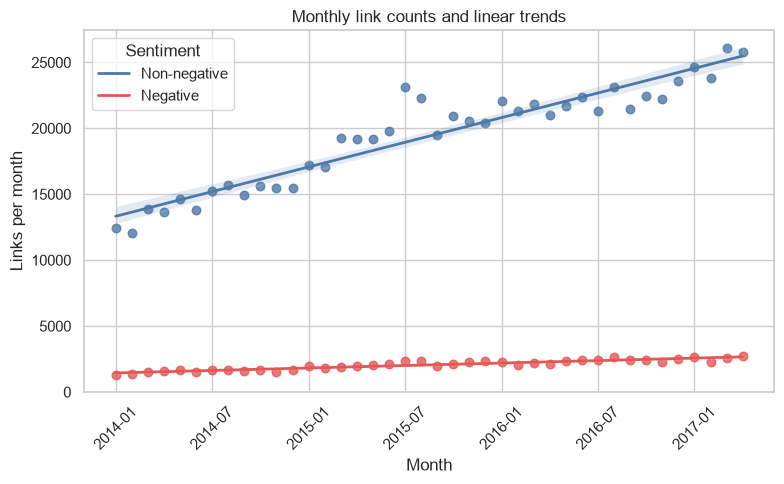

Non-negative: +1.70% per month
Negative: +1.60% per month
Negative share: -0.09% per month


,links,share
LINK_SENTIMENT,,
Non-negative,776278,90.42%
Negative,82210,9.58%


In [5]:
# Count links by month and sentiment; omit the partial first month.
monthly = (links.assign(month=links["time"].dt.to_period("M").dt.to_timestamp())
           .groupby(["month", "LINK_SENTIMENT"]).size().unstack(fill_value=0))
monthly = monthly.loc[monthly.index >= "2014-01-01"].rename(
    columns={1: "Non-negative", -1: "Negative"}).reset_index()
monthly["month_number"] = np.arange(len(monthly))

fig, ax = plt.subplots(figsize=(8, 5))
sns.regplot(data=monthly, x="month_number", y="Non-negative", ax=ax, color="#4C78A8",
            ci=95, scatter_kws={"s": 38, "alpha": 0.8}, line_kws={"linewidth": 2})
sns.regplot(data=monthly, x="month_number", y="Negative", ax=ax, color="#E45756",
            ci=95, scatter_kws={"s": 38, "alpha": 0.8}, line_kws={"linewidth": 2})
tick_positions = np.arange(0, len(monthly), 6)
ax.set_xticks(tick_positions, monthly.loc[tick_positions, "month"].dt.strftime("%Y-%m"), rotation=45)
ax.set(title="Monthly link counts and linear trends", xlabel="Month",
       ylabel="Links per month", ylim=(0, None))
ax.legend(handles=ax.lines[:2], labels=["Non-negative", "Negative"], title="Sentiment")
fig.tight_layout()
plt.show()

# Log-linear fits express the typical monthly change on a comparable percentage scale.
monthly["Negative share"] = monthly["Negative"] / (monthly["Negative"] + monthly["Non-negative"])
for label in ["Non-negative", "Negative", "Negative share"]:
    log_slope = np.polyfit(monthly["month_number"], np.log(monthly[label]), 1)[0]
    monthly_growth = np.expm1(log_slope)
    print(f"{label}: {monthly_growth:+.2%} per month")

totals = links["LINK_SENTIMENT"].value_counts().rename(index={1: "Non-negative", -1: "Negative"})
display(pd.DataFrame({"links": totals, "share": totals / totals.sum()}).style.format({"share": "{:.2%}"}))

The two count series grow at similar fitted monthly rates: 1.70% for non-negative links and 1.60% for negative links. The negative share changes by about -0.09% per month on this relative scale, so it remains close to one tenth of all links. This is a relative percent change in the share, not a change of 0.09 percentage points. Later response comparisons use rates within each selected-link group and state their denominators.

## 2. Select the second observed link in each pair

We use the full observation period. Each pair enters the analysis if its first recorded link is non-negative and it has a second recorded link with at least 30 days of data remaining. The second link is the selected event: it may be negative or non-negative. This gives both groups exactly one earlier interaction and one event per pair.

The first link may be in either direction. For a selected A → B link, `prior_reverse` means that the first link was B → A. We cannot know whether the dataset captured the pair’s first-ever interaction; pairs whose first recorded link is negative or that have only one recorded link are outside this analysis.

In [6]:
# Identify the first and second recorded links of each unordered pair.
pair = links.groupby(["pair_a", "pair_b"], sort=False)
links["position_in_pair"] = pair.cumcount()
links["first_sentiment"] = pair["LINK_SENTIMENT"].transform("first")
links["first_source"] = pair["SOURCE_SUBREDDIT"].transform("first")

follow_up = pd.Timedelta(30, unit="D")
# Keep the second link if the first was non-negative and 30 days remain.
events = links.loc[
    links["position_in_pair"].eq(1)
    & links["first_sentiment"].eq(1)
    & links["time"].le(links["time"].max() - follow_up)
].copy()
events["negative_event"] = events["LINK_SENTIMENT"].eq(-1)
# With one prior link, a different first source means that link ran in reverse.
events["prior_reverse"] = events["SOURCE_SUBREDDIT"].ne(events["first_source"]).astype(bool)
events["group"] = events["negative_event"].map({False: "Non-negative", True: "Negative"})
event_mix = events.groupby("group").agg(
    pairs=("POST_ID", "size"), opposite_direction_share=("prior_reverse", "mean"))
event_mix["same_direction_share"] = 1 - event_mix["opposite_direction_share"]
display(event_mix[["pairs", "same_direction_share", "opposite_direction_share"]]
        .style.format({"same_direction_share": "{:.2%}",
                       "opposite_direction_share": "{:.2%}"}))

,pairs,same_direction_share,opposite_direction_share
group,,,
Negative,5946,87.17%,12.83%
Non-negative,75067,77.76%,22.24%


The first two observed links usually run in the same direction. This is especially true when the second link is negative: 87.17% repeat the first link’s direction, compared with 77.76% when the second link is non-negative. An early negative link is therefore more often a change in tone from the same source community than a negative link coming from the community that was linked to first.

## 3. Does the other community link back?

We search for the first link in the direction opposite to the selected second link, allowing same-direction links in between. We count a reverse link only if it arrives within 30 days.

In [7]:
# The next link between the pair may run in either direction.
links["next_pair_time"] = pair["time"].shift(-1)
events["next_pair_time"] = links.loc[events.index, "next_pair_time"].to_numpy()
events["another_link_30d"] = (events["next_pair_time"] - events["time"]).le(follow_up)

# Swap source and target on the right to find the next link in the reverse direction.
reverse_links = links[["SOURCE_SUBREDDIT", "TARGET_SUBREDDIT", "time", "LINK_SENTIMENT"]].rename(
    columns={"SOURCE_SUBREDDIT": "TARGET_SUBREDDIT",
             "TARGET_SUBREDDIT": "SOURCE_SUBREDDIT",
             "time": "reverse_time", "LINK_SENTIMENT": "reverse_sentiment"})
event_lookup = events[["SOURCE_SUBREDDIT", "TARGET_SUBREDDIT", "time"]].copy()
event_lookup["event_id"] = event_lookup.index
matched = pd.merge_asof(
    event_lookup.sort_values("time"),
    reverse_links.sort_values("reverse_time"),
    left_on="time", right_on="reverse_time",
    by=["SOURCE_SUBREDDIT", "TARGET_SUBREDDIT"],
    direction="forward", allow_exact_matches=False,
)
matched = matched.set_index("event_id")
events["reverse_time"] = matched["reverse_time"]
events["reverse_sentiment"] = matched["reverse_sentiment"]
events["reverse_30d"] = (events["reverse_time"] - events["time"]).le(follow_up)
events["negative_reverse_30d"] = events["reverse_30d"] & events["reverse_sentiment"].eq(-1)

### 3.1 Main comparison: the direction of the first link

The selected second link can repeat the first link’s direction or run in the opposite direction. These are different starting situations: a pair with opposite-direction links has already linked both ways. We compare response rates and the sentiment of first reverse links within each situation.

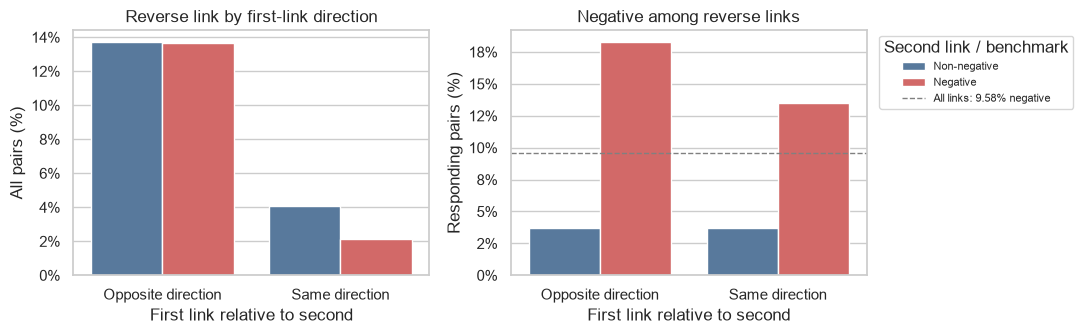

In [8]:
# Compare outcomes by the direction of the first observed link.
events["first_link_direction"] = events["prior_reverse"].map(
    {False: "Same direction", True: "Opposite direction"})
by_direction = events.groupby(["first_link_direction", "group"], observed=True).agg(
    pairs=("POST_ID", "size"), reverse_30d=("reverse_30d", "sum"),
    negative_reverse_30d=("negative_reverse_30d", "sum"))
by_direction["reverse_rate"] = by_direction["reverse_30d"] / by_direction["pairs"]
by_direction["negative_given_reverse"] = (
    by_direction["negative_reverse_30d"] / by_direction["reverse_30d"])
display(by_direction[["reverse_rate", "negative_given_reverse", "pairs", "reverse_30d"]]
        .style.format({"reverse_rate": "{:.2%}", "negative_given_reverse": "{:.2%}"}))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
plot_data = by_direction.reset_index()
for ax, column, title, ylabel in [
    (axes[0], "reverse_rate", "Reverse link by first-link direction", "All pairs (%)"),
    (axes[1], "negative_given_reverse", "Negative among reverse links", "Responding pairs (%)")
]:
    sns.barplot(data=plot_data, x="first_link_direction", y=column, hue="group",
                hue_order=["Non-negative", "Negative"], palette=["#4C78A8", "#E45756"], ax=ax)
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda value, _: f"{value:.0%}"))
    ax.set(title=title, xlabel="First link relative to second", ylabel=ylabel)
    ax.legend_.remove()
baseline = links["LINK_SENTIMENT"].eq(-1).mean()
axes[1].axhline(baseline, color="gray", linestyle="--", linewidth=1,
                label=f"All links: {baseline:.2%} negative")
axes[1].legend(title="Second link / benchmark", loc="upper left",
               bbox_to_anchor=(1.02, 1), fontsize=8)
fig.tight_layout()
plt.show()

The pair’s first two directions are strongly associated with whether it links back again. If those links already ran in opposite directions, about 13.7% of pairs have a reverse link within 30 days, regardless of whether the second link was negative. If both links ran in the same direction, the rate is much lower: 2.14% after a negative second link and 4.06% after a non-negative one.

Sentiment shows a different pattern on the right. In both direction groups, the first reverse link is more often negative after a negative second link than after a non-negative one. The dashed line marks the 9.58% negative share across all links in the dataset: the negative-second-link bars lie above it, and the non-negative-second-link bars below it. This benchmark gives context, although all links are not a matched sample of reverse links.

### 3.2 Overall rates across both direction groups

The pooled table summarizes all selected pairs, but it combines the two starting situations above. `another_link_rate` counts a later link in either direction within 30 days. `reverse_rate` counts only a link from the target back to the source. `negative_given_reverse` is the negative share of first reverse links among pairs that link back. The plot shows the last two rates with 95% Wilson intervals.

,another_link_rate,reverse_rate,negative_given_reverse
group,,,
Non-negative,23.12%,6.21%,3.69%
Negative,22.40%,3.62%,15.81%


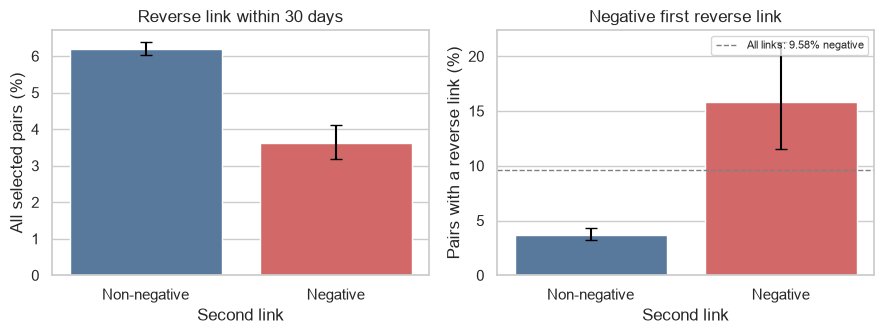

In [9]:
# Compare rates because the two event groups have different sizes.
response = events.groupby("group").agg(
    pairs=("POST_ID", "size"), another_link_30d=("another_link_30d", "sum"),
    reverse_30d=("reverse_30d", "sum"), negative_reverse_30d=("negative_reverse_30d", "sum"),
).reindex(["Non-negative", "Negative"])
response["another_link_rate"] = response["another_link_30d"] / response["pairs"]
response["reverse_rate"] = response["reverse_30d"] / response["pairs"]
response["negative_given_reverse"] = response["negative_reverse_30d"] / response["reverse_30d"]
display(response[["another_link_rate", "reverse_rate", "negative_given_reverse"]].style.format(
    {"another_link_rate": "{:.2%}", "reverse_rate": "{:.2%}",
     "negative_given_reverse": "{:.2%}"}))

# Wilson intervals convey the greater uncertainty among negative-event responders.
fig, axes = plt.subplots(1, 2, figsize=(9, 3.5))
comparisons = [("reverse_30d", "pairs", "Reverse link within 30 days", "All selected pairs (%)"),
               ("negative_reverse_30d", "reverse_30d", "Negative first reverse link", "Pairs with a reverse link (%)")]
for ax, (numerator, denominator, title, ylabel) in zip(axes, comparisons):
    successes, totals = response[numerator].to_numpy(), response[denominator].to_numpy()
    rates = successes / totals
    lower, upper = proportion_confint(successes, totals, method="wilson")
    sns.barplot(x=response.index, y=rates * 100, hue=response.index, legend=False,
                palette={"Non-negative": "#4C78A8", "Negative": "#E45756"}, ax=ax)
    ax.errorbar(range(2), rates * 100, yerr=[(rates - lower) * 100, (upper - rates) * 100],
                fmt="none", color="black", capsize=4)
    ax.set(title=title, xlabel="Second link", ylabel=ylabel)
    if numerator == "negative_reverse_30d":
        baseline = links["LINK_SENTIMENT"].eq(-1).mean() * 100
        ax.axhline(baseline, color="gray", linestyle="--", linewidth=1,
                   label=f"All links: {baseline:.2f}% negative")
        ax.legend(loc="upper right", fontsize=8)
fig.tight_layout()
plt.show()

Across both direction groups, reverse links are less frequent after a negative second link (3.62% versus 6.21%). This pooled gap partly reflects that negative second links less often occur in pairs that have already linked both ways. Among pairs that do link back, a negative first reverse link is much more common after a negative second link (15.81% versus 3.69%). The dashed 9.58% line is the negative share of all dataset links: useful context, but not a matched reply comparison.

### 3.3 Pooled time-window sensitivity

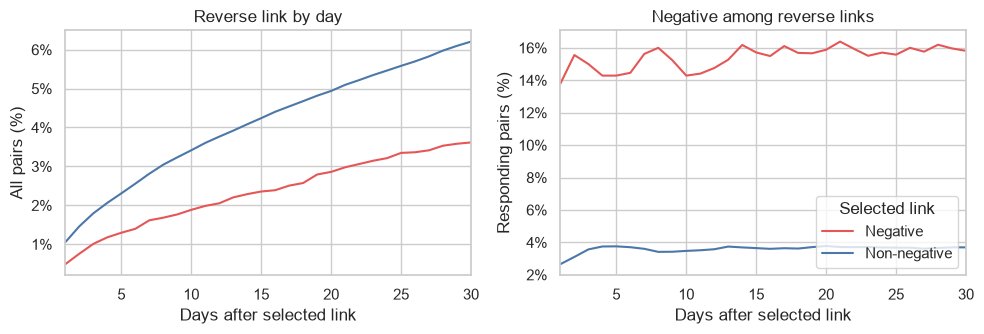

In [10]:
# Use the same eligible pairs for every window; all have at least 30 days of coverage.
windows = []
for days in range(1, 31):
    reverse = (events["reverse_time"] - events["time"]).le(pd.Timedelta(days, unit="D"))
    for group, subset in events.groupby("group"):
        came_back = reverse.loc[subset.index]
        negative_back = came_back & subset["reverse_sentiment"].eq(-1)
        windows.append({"days": days, "group": group, "pairs": len(subset),
                        "reverse": came_back.sum(), "negative_reverse": negative_back.sum(),
                        "reverse_rate": came_back.mean(),
                        "negative_given_reverse": negative_back.sum() / came_back.sum() if came_back.sum() else np.nan})
window_table = pd.DataFrame(windows)
display(window_table.loc[window_table["days"].isin([7, 30])]
        .set_index(["days", "group"])[["reverse_rate", "negative_given_reverse", "pairs", "reverse"]].style.format(
            {"reverse_rate": "{:.2%}", "negative_given_reverse": "{:.2%}"}))

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
for ax, column, title, ylabel in [
    (axes[0], "reverse_rate", "Reverse link by day", "All pairs (%)"),
    (axes[1], "negative_given_reverse", "Negative among reverse links", "Responding pairs (%)")
]:
    sns.lineplot(data=window_table, x="days", y=column, hue="group", ax=ax,
                 palette={"Non-negative": "#4C78A8", "Negative": "#E45756"})
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda value, _: f"{value:.0%}"))
    ax.set(title=title, xlabel="Days after selected link", ylabel=ylabel, xlim=(1, 30))
    ax.legend_.remove()
axes[1].legend(title="Selected link", loc="lower right")
fig.tight_layout()
plt.show()

The 30-day result is not specific to that cutoff. Across shorter and longer windows, non-negative second links are consistently followed by more reverse links than negative second links. Both curves on the left rise as the window grows: with more time, more pairs have a chance to produce a reverse link. On the right, the negative share among first reverse links changes relatively little with the window. It stays higher after a negative second link than after a non-negative one. These are pooled curves across the two first-link direction groups, which the main comparison separates.

### 3.4 Adjustment for prior direction and calendar time

We model the reverse-link outcome with an interaction between second-link sentiment and prior direction, so the sentiment association may differ across the two starting situations. For negativity among responders, we use the same covariates without an interaction. Both models include year and title/body location, with standard errors clustered by target subreddit.

For the reverse-link outcome, the main terms are

$$\operatorname{logit}\bigl(P(Y_i=1)\bigr)=\beta_0+\beta_1\mathrm{NegativeLink}_i+\beta_2\mathrm{PriorReverse}_i+\beta_3(\mathrm{NegativeLink}_i\times\mathrm{PriorReverse}_i)+\gamma_{\mathrm{year}(i)}+\delta_{\mathrm{location}(i)}.$$

The conditional sentiment model omits the interaction. Both describe associations, not causal effects.

In [11]:
# Allow the sentiment association with a reverse link to differ by prior direction.
events["negative_link"] = events["negative_event"].astype(int)
events["prior_reverse_int"] = events["prior_reverse"].astype(int)
events["year"] = events["time"].dt.year.astype(str)
events["reverse_outcome"] = events["reverse_30d"].astype(int)
events["negative_reverse_outcome"] = events["negative_reverse_30d"].astype(int)

reverse_model = smf.logit(
    "reverse_outcome ~ negative_link * prior_reverse_int + C(year) + C(LOCATION)",
    data=events).fit(disp=False, cov_type="cluster",
                     cov_kwds={"groups": events["TARGET_SUBREDDIT"]})
responders = events.loc[events["reverse_30d"]]
sentiment_model = smf.logit(
    "negative_reverse_outcome ~ negative_link + prior_reverse_int + C(year) + C(LOCATION)",
    data=responders).fit(disp=False, cov_type="cluster",
                         cov_kwds={"groups": responders["TARGET_SUBREDDIT"]})

# The negative-link coefficient is for same-direction pairs; add the interaction for opposite-direction pairs.
base = reverse_model.params["negative_link"]
interaction = reverse_model.params["negative_link:prior_reverse_int"]
cov = reverse_model.cov_params()
same_se = np.sqrt(cov.loc["negative_link", "negative_link"])
opposite_se = np.sqrt(cov.loc["negative_link", "negative_link"]
                      + cov.loc["negative_link:prior_reverse_int", "negative_link:prior_reverse_int"]
                      + 2 * cov.loc["negative_link", "negative_link:prior_reverse_int"])
sentiment_beta = sentiment_model.params["negative_link"]
sentiment_se = sentiment_model.bse["negative_link"]
model_rows = [("Reverse link: same direction", base, same_se),
              ("Reverse link: opposite direction", base + interaction, opposite_se),
              ("Negative if reversed", sentiment_beta, sentiment_se)]
model_table = pd.DataFrame([
    {"outcome": label, "odds_ratio": np.exp(beta),
     "ci_low": np.exp(beta - 1.96 * se), "ci_high": np.exp(beta + 1.96 * se)}
    for label, beta, se in model_rows]).set_index("outcome")
display(model_table.style.format({"odds_ratio": "{:.2f}",
                                  "ci_low": "{:.2f}", "ci_high": "{:.2f}"}))

,odds_ratio,ci_low,ci_high
outcome,,,
Reverse link: same direction,0.52,0.43,0.64
Reverse link: opposite direction,1.00,0.80,1.26
Negative if reversed,4.80,3.20,7.21


After adjusting for year and title/body location, a negative second link is associated with lower odds of a 30-day reverse link when the first two links ran in the same direction (odds ratio 0.52, 95% CI 0.43–0.64). When those links ran in opposite directions, the adjusted odds ratio is 1.00 (95% CI 0.80–1.26): there is no clear response-rate difference by second-link sentiment in that group. Among pairs that do link back, a negative second link is associated with a more negative first reverse link (odds ratio 4.80, 95% CI 3.20–7.21). These are descriptive associations, not causal effects.

### 3.5 One observed pair, as a timeline

The plot below is a concrete example of the sequence we measure. We select a pair with a negative first reverse link so both parts of the question are visible. It illustrates the definition; it is not selected as a representative pair.

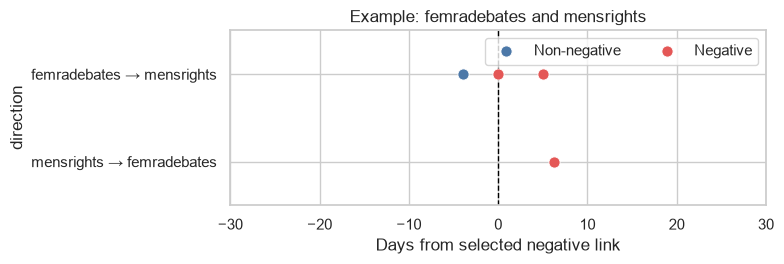

In [12]:
returned = events.loc[events["reverse_30d"]].copy()
example = returned.loc[returned["negative_event"] & returned["negative_reverse_30d"]].sort_values(
    ["time", "pair_a", "pair_b"]).iloc[0]
example_links = links.loc[
    links["pair_a"].eq(example["pair_a"]) & links["pair_b"].eq(example["pair_b"])
    & links["time"].between(example["time"] - follow_up, example["time"] + follow_up)
].copy()
example_links["days_from_event"] = (
    example_links["time"] - example["time"]).dt.total_seconds() / 86400
example_links["direction"] = np.where(
    example_links["SOURCE_SUBREDDIT"].eq(example["SOURCE_SUBREDDIT"]), 1, 0)

# Show one observed sequence, not a representative pair.
fig, ax = plt.subplots(figsize=(8, 2.8))
for sentiment, color, label in [(1, "#4C78A8", "Non-negative"),
                                (-1, "#E45756", "Negative")]:
    part = example_links.loc[example_links["LINK_SENTIMENT"].eq(sentiment)]
    sns.scatterplot(x=part["days_from_event"], y=part["direction"], ax=ax,
               s=65, color=color, label=label, zorder=3)
ax.axvline(0, color="black", linestyle="--", linewidth=1)
ax.set(xlim=(-30, 30), ylim=(-0.5, 1.5), xlabel="Days from selected negative link",
       title=f"Example: {example['SOURCE_SUBREDDIT']} and {example['TARGET_SUBREDDIT']}")
ax.set_yticks([0, 1], [f"{example['TARGET_SUBREDDIT']} → {example['SOURCE_SUBREDDIT']}",
                        f"{example['SOURCE_SUBREDDIT']} → {example['TARGET_SUBREDDIT']}"])
ax.legend(loc="upper right", ncol=2)
fig.tight_layout()
plt.show()

## 4. Separate full-history view: is negativity mutual?

This second view describes full observed pair histories, rather than the 30-day event sample. We keep pairs with at least five links in each direction. We classify a direction as negative when at least 20% of its recorded links are negative. This activity cutoff and share threshold are descriptive choices, not natural boundaries.

In [13]:
# Summarize the entire observed history in each direction.
directions = links.groupby(["pair_a", "pair_b", "SOURCE_SUBREDDIT"]).agg(
    links=("LINK_SENTIMENT", "size"),
    negative_links=("LINK_SENTIMENT", lambda x: x.eq(-1).sum()),
).reset_index()
directions["negative_share"] = directions["negative_links"] / directions["links"]
active = directions.loc[directions["links"].ge(5)].copy()
active["negative_direction"] = active["negative_share"].ge(0.20)
pairs_both = active.groupby(["pair_a", "pair_b"]).filter(lambda x: len(x) == 2)
pair_types = pairs_both.groupby(["pair_a", "pair_b"])["negative_direction"].sum().map(
    {0: "Neither direction", 1: "One direction", 2: "Both directions"})
counts = pair_types.value_counts().reindex(
    ["Neither direction", "One direction", "Both directions"], fill_value=0)
print(f"Active reciprocal pairs: {len(pair_types):,}")
display(pd.DataFrame({"pairs": counts, "share": counts / counts.sum()}).style.format({"share": "{:.2%}"}))

Active reciprocal pairs: 3,410


,pairs,share
negative_direction,,
Neither direction,2928,85.87%
One direction,352,10.32%
Both directions,130,3.81%


## 5. Takeaway and limits

The second-link design compares pairs after a first non-negative link. The direction of their first two links is central to whether a reverse link appears next: pairs that have already linked both ways are much more likely to link back within 30 days. Within that group, the reverse-link rate barely differs by the second link’s sentiment. When both initial links ran the same way, a negative second link is followed by fewer reverse links than a non-negative one.

For the pairs that do link back, sentiment tells a different story. Their first reverse link is negative in 15.81% of cases after a negative second link and 3.69% after a non-negative one. The 9.58% negative share among all dataset links provides context for these conditional figures, though it is not a matched reply benchmark.

The full-history classification above uses a different sample. It describes whether established reciprocal pairs have negativity in one or both directions.

The dataset begins around 2014, so earlier interactions are unseen. Sentiment labels are classifier outputs, and the second-link groups can differ in ways we do not measure. A later reverse link is an observed sequence, not proof of a reply or retaliation.